# Regression Model

## NYC Yellow Taxi Fare Prediction — August 2026

## Importing Libraries

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score


## Loading Dataset

In [5]:

filename = "Cleaned_yellow_tripdata_2026-08.parquet"

possible_paths = [
    Path(filename),
    Path("Processed") / filename,
    Path("../Processed") / filename
]

file_path = next(
    (p for p in possible_paths if p.is_file()),
    None
)

if file_path is None:
    raise FileNotFoundError(
        "Cleaned August 2026 dataset not found."
    )

df = pd.read_parquet(file_path)

df.head()


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,...,Airport_fee,cbd_congestion_fee,trip_duration_min,pickup_hour,pickup_day,pickup_weekday,is_weekend,revenue_per_mile,revenue_per_minute,tip_percentage
0,1,2026-08-01 00:03:04,2026-08-01 00:07:51,1.0,0.60,1.0,140,262,1,6.5,...,0.0,0.00,4.783333,0,1,5,1,23.00,2.89,0.3538
1,1,2026-08-01 00:38:45,2026-08-01 00:44:02,1.0,0.70,1.0,140,262,1,6.5,...,0.0,0.00,5.283333,0,1,5,1,21.36,2.83,0.5308
2,1,2026-08-01 00:54:51,2026-08-01 01:01:07,1.0,1.10,1.0,140,263,1,7.9,...,0.0,0.00,6.266667,0,1,5,1,14.09,2.47,0.3291
3,2,2026-08-01 00:27:35,2026-08-01 00:54:27,1.0,5.24,1.0,164,80,1,29.6,...,0.0,0.75,26.866667,0,1,5,1,9.80,1.91,0.2892
4,2,2026-08-01 00:39:08,2026-08-01 01:00:23,1.0,3.57,1.0,148,141,1,20.5,...,0.0,0.75,21.250000,0,1,5,1,8.82,1.48,0.2561


## Feature Selection

In [7]:

features = ["trip_distance", "trip_duration_min"]
target = "fare_amount"

X = df[features]
y = df[target]


## Train-Test Split

In [8]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## Training Linear Regression Model

In [9]:

model = LinearRegression()

model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


## Predictions


In [10]:

y_pred = model.predict(X_test)

y_pred


array([24.535887  , 24.1196618 , 20.18251687, ..., 19.75303186,
       16.84869715, 19.17601748], shape=(632649,))

## Evaluating Model

In [11]:

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean absolute error :", mae)
print("r2 score :", r2)


Mean absolute error : 9.548785222262788
r2 score : 0.19297025993408545


## Model Coefficients

In [12]:

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

coefficients


,Feature,Coefficient
0,trip_distance,0.000372
1,trip_duration_min,0.303502


## Actual vs Predicted Fare

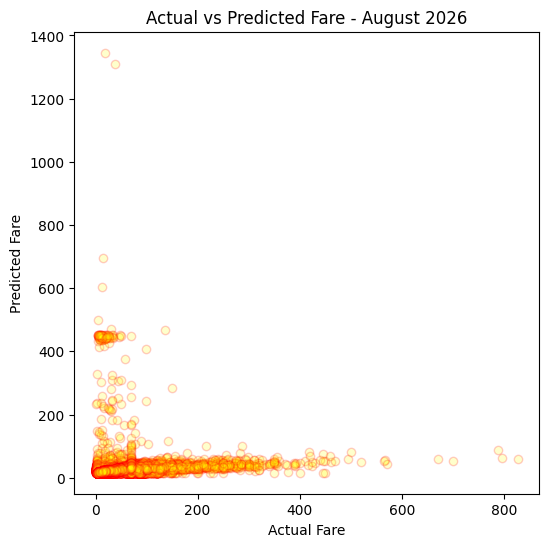

In [13]:

plt.figure(figsize=(6,6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.2,
    color="yellow",
    edgecolor="red"
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare - August 2026")

plt.show()
